# Sentiment Analysis

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from datasets import load_dataset

c:\Projects\DL Projects\Sentiment Analysis\myvenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
emotional_dataset = load_dataset('dair-ai/emotion')
train_text = emotional_dataset['train']['text']
train_label = emotional_dataset['train']['label']

test_text = emotional_dataset['test']['text']
test_label = emotional_dataset['test']['label']

In [4]:
train_label

Column([0, 0, 3, 2, 3, ...])

In [5]:
label_names = emotional_dataset['train'].features['label'].names
label_names

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [6]:
df_train = pd.DataFrame(
    {
        'text' : train_text,
        'label' : [label_names[i] for i in train_label]
    }
)

df_test = pd.DataFrame(
    {
        'text' : test_text,
        'label' : [label_names[i] for i in test_label]
    }
)

In [7]:
df_train.head()

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [8]:
df_train.shape

(16000, 2)

In [9]:
df_train.isnull().sum()

text     0
label    0
dtype: int64

In [10]:
df_train.duplicated().sum()

np.int64(1)

### EDA

In [11]:
df_train['label'].value_counts().index

Index(['joy', 'sadness', 'anger', 'fear', 'love', 'surprise'], dtype='str', name='label')

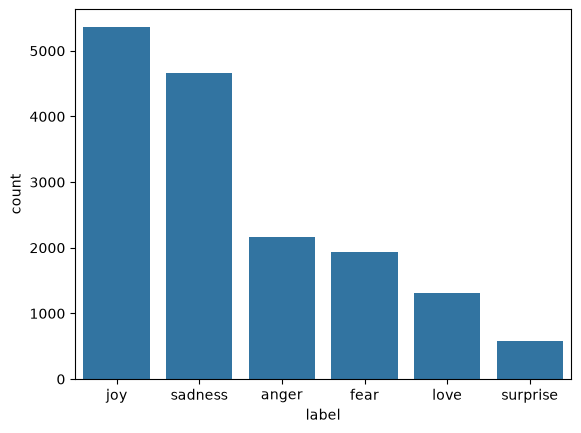

In [12]:
sns.countplot(x='label' , data=df_train, order=df_train['label'].value_counts().index)
plt.show()

### Preprocessing Using NLP

In [13]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

max_words = 10_000

tokenizer = Tokenizer(num_words=max_words, oov_token='<unk>') 
tokenizer.fit_on_texts(df_train['text'])   #give more importance to unique numbers

train_sequence = tokenizer.texts_to_sequences(df_train['text'])  #remove text and accept only number
test_sequence = tokenizer.texts_to_sequences(df_test['text'])

padded_train_sequence = pad_sequences(train_sequence, maxlen=50 , padding='post', truncating='post') #padding 0 to make input equal size
padded_test_sequence = pad_sequences(test_sequence, maxlen=50 , padding='post', truncating='post')

train_label = np.array(train_label)
test_label = np.array(test_label)

num_classess = len((np.unique(train_label)))

print(f"Vocabulary Size :{len(tokenizer.word_index)}")
print(f"Max Sentence Length : {padded_train_sequence.shape[1]}")

Vocabulary Size :15213
Max Sentence Length : 50


### Handling class imbalance

In [14]:
from sklearn.utils import class_weight

class_weight = class_weight.compute_class_weight(
    class_weight= 'balanced',
    classes = np.unique(train_label),
    y       =  train_label
)

class_weight_dict = dict(enumerate(class_weight))

### Early Stopping

In [15]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor= 'val_loss',
    patience= 3,
    restore_best_weights=True
)

### Phase 1


### Simple RNN Model

In [16]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Embedding, Dense, Dropout, LSTM, GRU


rnn_model = Sequential([
    Embedding(input_dim= max_words, output_dim=128, input_length=50),
    SimpleRNN(units=128, return_sequences=True),
    Dropout(0.5),
    SimpleRNN(units=64),
    Dropout(0.5),
    Dense(units=num_classess, activation='softmax') #output layer
])

rnn_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

c:\Projects\DL Projects\Sentiment Analysis\myvenv\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [17]:
rnn_model.fit(
    padded_train_sequence,
    train_label,
    validation_data = (padded_test_sequence, test_label),
    epochs = 20,
    batch_size = 32,
    class_weight = class_weight_dict,
    callbacks = [early_stopping]
)

rnn_loss, rnn_accuracy = rnn_model.evaluate(padded_test_sequence, test_label)
print(f"RNN Loss: {rnn_loss}")
print(f"RNN Accuracy: {rnn_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 23s 37ms/step - accuracy: 0.1609 - loss: 2.0704 - val_accuracy: 0.2045 - val_loss: 1.7241
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 18s 37ms/step - accuracy: 0.1447 - loss: 1.8862 - val_accuracy: 0.1365 - val_loss: 1.8358
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 18s 36ms/step - accuracy: 0.1398 - loss: 1.8170 - val_accuracy: 0.0440 - val_loss: 1.8498
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 18s 36ms/step - accuracy: 0.1265 - loss: 1.8073 - val_accuracy: 0.3210 - val_loss: 1.7644
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.2045 - loss: 1.7241
RNN Loss: 1.7241255044937134
RNN Accuracy: 0.2045000046491623


### LSTM Model

In [18]:
lstm_model = Sequential([
    Embedding(input_dim= max_words, output_dim=128, input_length=50),
    LSTM(units=128, return_sequences=True),
    Dropout(0.5),
    LSTM(units=64),
    Dropout(0.5),
    Dense(units=num_classess, activation='softmax') #output layer
])

lstm_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])


lstm_model.fit(
    padded_train_sequence,
    train_label,
    validation_data = (padded_test_sequence, test_label),
    epochs = 20,
    batch_size = 32,
    class_weight = class_weight_dict,
    callbacks = [early_stopping]
)

lstm_loss, lstm_accuracy = lstm_model.evaluate(padded_test_sequence, test_label)
print(f"LSTM Loss: {lstm_loss}")
print(f"LSTM Accuracy: {lstm_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 42s 76ms/step - accuracy: 0.1381 - loss: 1.7944 - val_accuracy: 0.1440 - val_loss: 1.7577
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 37s 74ms/step - accuracy: 0.1459 - loss: 1.7944 - val_accuracy: 0.1365 - val_loss: 1.7922
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 38s 76ms/step - accuracy: 0.1560 - loss: 1.7956 - val_accuracy: 0.1870 - val_loss: 1.7922
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 38s 76ms/step - accuracy: 0.1372 - loss: 1.7920 - val_accuracy: 0.1025 - val_loss: 1.7815
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.1440 - loss: 1.7577
LSTM Loss: 1.7576736211776733
LSTM Accuracy: 0.14399999380111694


### GRU Model

In [19]:
gru_model = Sequential([
    Embedding(input_dim= max_words, output_dim=128, input_length=50),
    GRU(units=128, return_sequences=True),
    Dropout(0.5),
    GRU(units=64),
    Dropout(0.5),
    Dense(units=num_classess, activation='softmax') #output layer
])

gru_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])


gru_model.fit(
    padded_train_sequence,
    train_label,
    validation_data = (padded_test_sequence, test_label),
    epochs = 20,
    batch_size = 32,
    class_weight = class_weight_dict,
    callbacks = [early_stopping]
)

gru_loss, gru_accuracy = gru_model.evaluate(padded_test_sequence, test_label)
print(f"GRU Loss: {gru_loss}")
print(f"GRU Accuracy: {gru_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 39s 68ms/step - accuracy: 0.1525 - loss: 1.7966 - val_accuracy: 0.1380 - val_loss: 1.7845
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 33s 67ms/step - accuracy: 0.1521 - loss: 1.7951 - val_accuracy: 0.2905 - val_loss: 1.7979
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 33s 67ms/step - accuracy: 0.1536 - loss: 1.7944 - val_accuracy: 0.1390 - val_loss: 1.7969
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 32s 64ms/step - accuracy: 0.1582 - loss: 1.7912 - val_accuracy: 0.2775 - val_loss: 1.8046
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.1380 - loss: 1.7845
GRU Loss: 1.7844834327697754
GRU Accuracy: 0.1379999965429306


In [23]:
## Result 
result_df = pd.DataFrame({
    "Model" : ['RNN', 'LSTM', 'GRU'],
    'Test Loss': [rnn_loss, lstm_loss, gru_loss],
    'Test Accuracy': [rnn_accuracy,lstm_accuracy,gru_accuracy]
}).sort_values(by='Test Accuracy',ascending=False)

result_df

,Model,Test Loss,Test Accuracy
0,RNN,1.724126,0.2045
1,LSTM,1.757674,0.1440
2,GRU,1.784483,0.1380


### Phase 2
### Biderectional GRU

In [24]:
from tensorflow.keras.layers import Bidirectional


bigru = Sequential([
    Embedding(input_dim= max_words, output_dim=300, input_length=50),
    Bidirectional(GRU(128, return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(64)),
    Dropout(0.5),
    Dense(num_classess, activation='softmax') #output layer
])

bigru.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

bigru.summary()

c:\Projects\DL Projects\Sentiment Analysis\myvenv\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [25]:
bigru.fit(
    padded_train_sequence,
    train_label,
    validation_data = (padded_test_sequence, test_label),
    epochs = 20,
    batch_size = 32,
    class_weight = class_weight_dict,
    callbacks = [early_stopping]
)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 55s 91ms/step - accuracy: 0.5765 - loss: 1.0470 - val_accuracy: 0.8930 - val_loss: 0.3179
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 42s 84ms/step - accuracy: 0.9136 - loss: 0.2526 - val_accuracy: 0.9040 - val_loss: 0.2903
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 41s 83ms/step - accuracy: 0.9449 - loss: 0.1542 - val_accuracy: 0.9180 - val_loss: 0.2327
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 43s 85ms/step - accuracy: 0.9589 - loss: 0.1147 - val_accuracy: 0.9180 - val_loss: 0.2576
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 44s 87ms/step - accuracy: 0.9690 - loss: 0.0863 - val_accuracy: 0.9170 - val_loss: 0.2812
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 41s 82ms/step - accuracy: 0.9756 - loss: 0.0727 - val_accuracy: 0.9210 - val_loss: 0.3045


In [26]:
bigru_loss, bigru_accuracy = bigru.evaluate(padded_test_sequence, test_label)
print(f"BIGRU Loss: {bigru_loss}")
print(f"BIGRU Accuracy: {bigru_accuracy}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.9180 - loss: 0.2327
BIGRU Loss: 0.23270964622497559
BIGRU Accuracy: 0.9179999828338623


### Final Model Confusion Matricx

63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step


<Axes: >

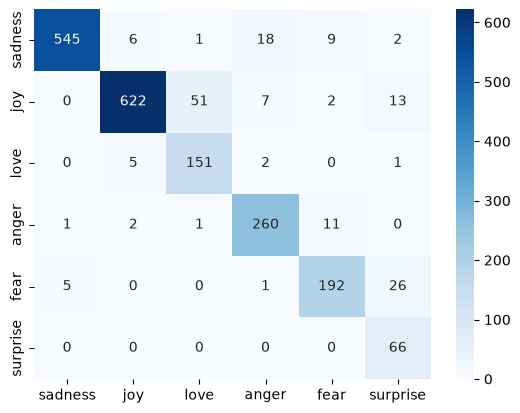

In [30]:
from sklearn.metrics import confusion_matrix

bigru_prediction = np.argmax(bigru.predict(padded_test_sequence), axis=1)

sns.heatmap(confusion_matrix(test_label, bigru_prediction),annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names)

### Check on Unseen Dataset

In [48]:
sample_texts = [
    "i feel so devastated and broken inside after losing my pet",
    "absolutely thrilled about winning the first prize in the competition",
    "i am deeply in love with your sweet personality",
    "it makes me furious when people are disrespectful to others",
    "i get incredibly anxious and terrified during heavy thunderstorms",
    "wow i never expected to see you walk through that door today",
    "sitting alone in the dark room feeling completely miserable",
    "we danced around the room full of pure delight and ecstasy",
    "holding hands under the stars felt so romantic and close",
    "he yelled out in pure rage and slammed his fists on the desk"
]

fixed_label_names = ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

sample_sequences = tokenizer.texts_to_sequences(sample_texts)
sample_padded_sequences = pad_sequences(sample_sequences, maxlen=50, padding='post', truncating='post')

sample_predictions = np.argmax(bigru.predict(sample_padded_sequences), axis=1)

for i in range(len(sample_texts)):
  print(f'Text: {sample_texts[i]}\nPredicted Emotion: {fixed_label_names[sample_predictions[i]]}')
     

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
Text: i feel so devastated and broken inside after losing my pet
Predicted Emotion: sadness
Text: absolutely thrilled about winning the first prize in the competition
Predicted Emotion: joy
Text: i am deeply in love with your sweet personality
Predicted Emotion: love
Text: it makes me furious when people are disrespectful to others
Predicted Emotion: anger
Text: i get incredibly anxious and terrified during heavy thunderstorms
Predicted Emotion: fear
Text: wow i never expected to see you walk through that door today
Predicted Emotion: fear
Text: sitting alone in the dark room feeling completely miserable
Predicted Emotion: sadness
Text: we danced around the room full of pure delight and ecstasy
Predicted Emotion: anger
Text: holding hands under the stars felt so romantic and close
Predicted Emotion: love
Text: he yelled out in pure rage and slammed his fists on the desk
Predicted Emotion: anger


### Save Model

In [49]:
import os
import pickle

model_dir = 'Artifacts'
os.makedirs(model_dir, exist_ok=True) #folder Created

#Save our bigru Model
bigru.save(os.path.join(model_dir, 'BiGRU_Modle.keras'))

#Save the tokenizer model
with open(os.path.join(model_dir, 'tokenizer.pkl'), 'wb') as file:
  pickle.dump(tokenizer, file)
     